# The selected data: RRUFF Raman RAW, confirmed, trimmed to 100 to 1250 cm-1

This notebook works on the training set chosen in `notebooks/rruff_raw.ipynb`,
where the decision and its reasoning are recorded in section 21. In short: the seven archives
under `~/Desktop/raman_data` are read, `LR-Raman` is left out, the files are filtered to the
`Raman RAW` exports whose identification some method has confirmed, and of those a file joins
the set when its data reaches from 100 cm-1 or lower up to somewhere in 1250 to 1350 cm-1. The
data kept from each such file is its 0 to 1350 cm-1 span, and each file is then trimmed to 100
to 1250 cm-1. That trimmed set is what this notebook describes.

Four things are reported about it: where the spectra come from, the spacing between
their points, the scale their intensities are on, and the values in them that a Raman
spectrum cannot take.


## 1. Setting up

The archives are looked for under `~/Desktop/raman_data` unless `RRUFF_DATA` points somewhere
else, so the notebook runs unchanged from another checkout. The window and the range it is taken
from are set here rather than in the cells below, since every count in the notebook is over them.


In [1]:
from __future__ import annotations

import os
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

# Categorical slots are taken in a fixed order and never cycled.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "text.color": INK,
    "font.size": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
})

# The seven archives read here, LR-Raman left out.
ARCHIVES = [
    "excellent_oriented",
    "excellent_unoriented",
    "fair_oriented",
    "fair_unoriented",
    "poor_unoriented",
    "unrated_oriented",
    "unrated_unoriented",
]

# The window the model sees, and the range of a file the data is taken from.
WINDOW_LOW, WINDOW_HIGH = 100.0, 1250.0
KEEP_LOW, KEEP_HIGH = 0.0, 1350.0

# RRUFF_DATA points the notebook at another extraction of the same archives.
DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

# Used by the reader below, which is why they are module level rather than inside it.
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
NUMBER = re.compile(r"[0-9]+(?:\.[0-9]+)?")
LEADING = "+-."

absent = [name for name in ARCHIVES if not (DATA_ROOT / name).is_dir()]
if absent:
    raise FileNotFoundError(f"these archive directories are missing under {DATA_ROOT}: {absent}")

print(f"reading {len(ARCHIVES)} archives from {DATA_ROOT}")
for name in ARCHIVES:
    print(f"  {name:22s} {len(list((DATA_ROOT / name).glob('*.txt'))):6,d} files")
print()
print(f"the model window is {WINDOW_LOW:.0f} to {WINDOW_HIGH:.0f} cm-1, taken from "
      f"{KEEP_LOW:.0f} to {KEEP_HIGH:.0f} cm-1 of each file")


reading 7 archives from /home/raj/Desktop/raman_data
  excellent_oriented      7,668 files
  excellent_unoriented   11,415 files
  fair_oriented              25 files
  fair_unoriented         2,951 files
  poor_unoriented         1,639 files
  unrated_oriented        3,778 files
  unrated_unoriented        639 files

the model window is 100 to 1250 cm-1, taken from 0 to 1350 cm-1 of each file


## 2. Reading one export

A file is a `##KEY=value` block, then the data rows. The three traps the reader has to survive
are the same ones the other notebook describes: a value wrapped onto the following line, a key
written twice, and comment lines mixed into the data block. The reader is repeated here in full
so this notebook runs on its own.


In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the header fields as a dict, and a dict describing the data block with the
        keys points, x_min, x_max, wrapped_values, repeated_keys, comment_notes,
        separator, crlf and encoding.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout


In [3]:
def read_block_rows(path):
    """The data rows of one export, with the header and any comment lines removed.

    Args:
        path (Path): the export to read.

    Returns:
        list: the stripped lines of the data block, in file order.
    """
    text = path.read_text(encoding="utf-8", errors="replace").replace("\r\n", "\n")
    lines = text.split("\n")

    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is not None and match.group(1).strip() == "END":
                body = position + 1
                break
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    break

    rows = []
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped or stripped.startswith("#"):
            continue
        rows.append(stripped)
    return rows


def read_values(path):
    """Read the two columns of one export's data block, on the same block rule as above.

    Args:
        path (Path): the export to read.

    Returns:
        list: (wavenumber, intensity) pairs, in file order.
    """
    values = []
    for row in read_block_rows(path):
        fields = row.replace(",", " ").split()
        if len(fields) == 2:
            try:
                values.append((float(fields[0]), float(fields[1])))
            except ValueError:
                pass
    return values


## 3. The files, and the two filters

One row per file, from the header pass. `FILETYPE` gives the export kind, so it is read from
that field rather than guessed from the file name, and the excitation wavelength comes from the
`RAMAN WAVELENGTH` field.


In [4]:
started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DATA_ROOT / archive).glob("*.txt")):
        header, layout = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        found = NUMBER.search(header.get("RAMAN WAVELENGTH", ""))
        records.append({
            "archive": archive,
            "path": str(path),
            "name": path.stem,
            "measurement": "__".join(path.stem.split("__")[:6]),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            "filetype": filetype,
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "wavelength_reported": header.get("RAMAN WAVELENGTH", ""),
            "wavelength_nm": float(found.group()) if found else np.nan,
            "status": header.get("STATUS", ""),
            "bytes": path.stat().st_size,
            **layout,
        })

pool = pd.DataFrame.from_records(records)
pool["spacing"] = (pool.x_max - pool.x_min) / (pool.points - 1).replace(0, np.nan)

print(f"read {len(pool):,} files in {time.time() - started:.1f}s, "
      f"{pool.bytes.sum() / 1e9:.2f} GB of text on disk")


read 28,115 files in 13.5s, 1.10 GB of text on disk


In [5]:
# An identification RRUFF records no confirmation for is written as "...is not yet
# confirmed" or as the bare "Unconfirmed". The markers are matched as substrings of the
# sentence so a wording omitting the "yet" is caught too.
UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")


def is_unconfirmed(status: str) -> bool:
    """Whether a STATUS sentence records no confirmation of the identification.

    Any method of confirmation counts, so a sentence naming X-ray diffraction, chemical
    analysis, Raman spectroscopy or any other technique returns False.

    Args:
        status (str): The STATUS field of one file, as written.

    Returns:
        bool: True if the sentence says the identification is not confirmed.
    """
    text = status.strip().lower()
    return any(marker in text for marker in UNCONFIRMED_MARKERS)


pool["unconfirmed"] = pool.status.map(is_unconfirmed)

raw = pool.kind == "RAW"
confirmed = ~pool.unconfirmed
kept = pool[raw & confirmed].copy()

table = pd.DataFrame({
    "confirmed": [int((raw & confirmed).sum()), int((~raw & confirmed).sum())],
    "unconfirmed": [int((raw & ~confirmed).sum()), int((~raw & ~confirmed).sum())],
}, index=["RAW", "Processed"])
table["files"] = table.sum(axis=1)
table.loc["all files"] = table.sum()
table = table.astype(int)

print(f"the pool:         {len(pool):8,d} files")
print(f"the kept set:     {len(kept):8,d} files ({len(kept) / len(pool) * 100:.1f}% of the pool)")
print()
print(table.to_string())


the pool:           28,115 files
the kept set:       13,154 files (46.8% of the pool)

           confirmed  unconfirmed  files
RAW            13154          954  14108
Processed      13054          953  14007
all files      26208         1907  28115


## 4. The window, and the trimmed set

The decision, as it is recorded in section 21 of `rruff_raw.ipynb`, is applied here
in three steps:

1. a file joins the set when its data reaches from 100 cm-1 or lower up to somewhere in 1250 to
   1350 cm-1, which is the band the earlier notebook's section 8 counts;
2. the data kept from each such file is its 0 to 1350 cm-1 span, so a wavenumber below zero
   is dropped, and the 1250 to 1350 cm-1 stretch is kept for the next step to trim;
3. each file is then trimmed to 100 to 1250 cm-1, and that trimmed set is the training data.

The cell reads every selected file in full once, trims it, and keeps the trimmed pair of columns
in `trimmed`, keyed by path, so the two sections below need no second pass over the archives.


In [6]:
chosen = kept[(kept.x_min <= WINDOW_LOW)
              & (kept.x_max >= WINDOW_HIGH)
              & (kept.x_max <= KEEP_HIGH)].copy()
print(f"kept files whose data reaches from {WINDOW_LOW:.0f} cm-1 or lower up to "
      f"{WINDOW_HIGH:.0f} to {KEEP_HIGH:.0f} cm-1: {len(chosen):,} of {len(kept):,} "
      f"({len(chosen) / len(kept) * 100:.2f}%)")
print(f"of those, opening below {KEEP_LOW:.0f} cm-1, so that part is dropped: "
      f"{int((chosen.x_min < KEEP_LOW).sum()):,}")
print()

started = time.time()
records = []
trimmed = {}
empty = 0
for row in chosen.itertuples():
    pair = np.asarray(read_values(Path(row.path)), dtype=float)
    if pair.ndim != 2 or pair.shape[0] == 0:
        empty += 1
        continue
    x, y = pair[:, 0], pair[:, 1]
    # One mask does the whole trim: points below WINDOW_LOW go, which covers the drop below
    # KEEP_LOW as well, and points above WINDOW_HIGH go, which is the 1250 to 1350 cm-1
    # stretch a selected file can hold.
    inside = (x >= WINDOW_LOW) & (x <= WINDOW_HIGH)
    if not inside.any():
        empty += 1
        continue
    trimmed[row.path] = (x[inside], y[inside])
    records.append({
        "path": row.path,
        "archive": row.archive,
        "mineral": row.mineral,
        "rruff_id": row.rruff_id,
        "wavelength_nm": row.wavelength_nm,
        "points": int(inside.sum()),
        "x_first": float(x[inside][0]),
        "x_last": float(x[inside][-1]),
        "spacing": float((x[inside][-1] - x[inside][0]) / max(int(inside.sum()) - 1, 1)),
        "y_min": float(y[inside].min()),
        "y_max": float(y[inside].max()),
    })

data = pd.DataFrame.from_records(records)
print(f"trimmed {len(data):,} files in {time.time() - started:.1f}s"
      f"{f', {empty} files held no point inside the window' if empty else ''}")
print(f"points in the trimmed set: {int(data.points.sum()):,}")
print(f"minerals: {data.mineral.nunique():,}, of them with two spectra or more: "
      f"{int((data.groupby('mineral').size() >= 2).sum()):,}")
print()
print("points per spectrum inside the window:")
print(data.points.describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_string())
print()
print(f"the first point inside the window sits at {data.x_first.min():.1f} to "
      f"{data.x_first.max():.1f} cm-1, median {data.x_first.median():.1f}")
print(f"the last point inside the window sits at {data.x_last.min():.1f} to "
      f"{data.x_last.max():.1f} cm-1, median {data.x_last.median():.1f}")


kept files whose data reaches from 100 cm-1 or lower up to 1250 to 1350 cm-1: 3,516 of 13,154 (26.73%)
of those, opening below 0 cm-1, so that part is dropped: 0



trimmed 3,516 files in 7.0s
points in the trimmed set: 8,282,885
minerals: 1,290, of them with two spectra or more: 1,126

points per spectrum inside the window:
count    3516.0
mean     2355.8
std       209.1
min       669.0
5%       2385.0
50%      2385.0
95%      2386.0
max      2948.0

the first point inside the window sits at 100.0 to 101.7 cm-1, median 100.2
the last point inside the window sits at 1248.6 to 1250.0 cm-1, median 1249.7


## 5. Where the spectra come from

Two source dimensions are counted here, by files and by points: the archive the file was read
from, and the excitation wavelength the file reports. Nothing in the selection separated spectra
by excitation wavelength, which is the last point of the reasoning recorded in section 21.


In [7]:
by_archive = data.groupby("archive").agg(
    files=("path", "size"),
    minerals=("mineral", "nunique"),
    points=("points", "sum"),
    points_med=("points", "median"),
)
by_archive["files_pct"] = (by_archive.files / len(data) * 100).round(2)
by_archive["points_pct"] = (by_archive.points / by_archive.points.sum() * 100).round(2)
print("the trimmed set by archive:")
print(by_archive.sort_values("files", ascending=False).to_string())
print()

by_wavelength = data.groupby(data.wavelength_nm.fillna(-1)).agg(
    files=("path", "size"),
    minerals=("mineral", "nunique"),
    points=("points", "sum"),
)
by_wavelength["files_pct"] = (by_wavelength.files / len(data) * 100).round(2)
print("the trimmed set by excitation wavelength:")
print(by_wavelength.rename(index={-1: "no number in RAMAN WAVELENGTH"}).to_string())
print()
print(f"files reporting no excitation wavelength: {int(data.wavelength_nm.isna().sum()):,}")


the trimmed set by archive:
                      files  minerals   points  points_med  files_pct  points_pct
archive                                                                          
excellent_unoriented   2524      1074  6000717      2385.0      71.79       72.45
fair_unoriented         489       365  1164801      2385.0      13.91       14.06
poor_unoriented         276       222   658340      2385.0       7.85        7.95
unrated_unoriented      174        80   412172      2385.0       4.95        4.98
excellent_oriented       38        14    33595       884.0       1.08        0.41
unrated_oriented         15         7    13260       884.0       0.43        0.16

the trimmed set by excitation wavelength:
                               files  minerals   points  files_pct
wavelength_nm                                                     
no number in RAMAN WAVELENGTH      1         1     2266       0.03
514.0                             66        28    58347       1.88
532.0

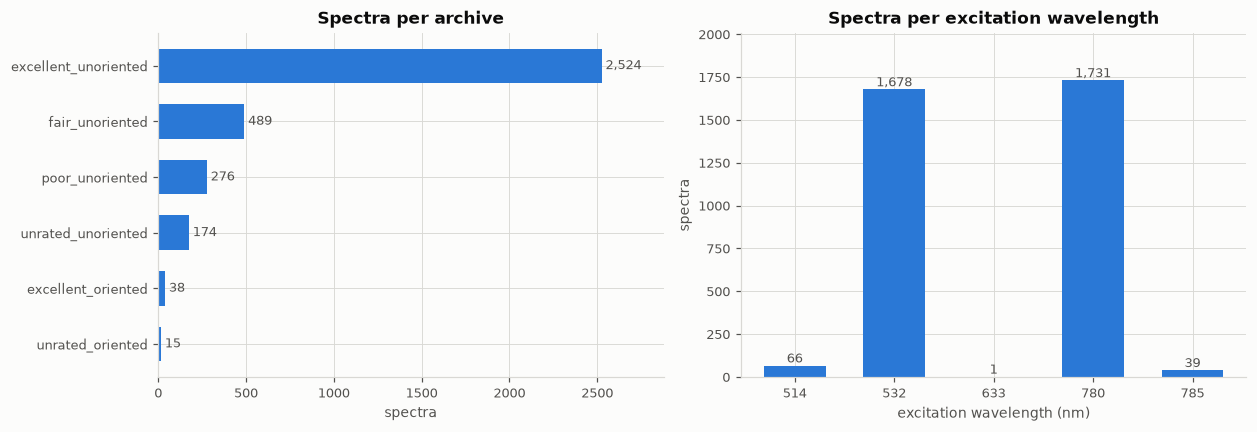

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

order = by_archive.sort_values("files").index
axes[0].barh(order, by_archive.loc[order, "files"], color=BLUE, height=0.62)
for y, name in enumerate(order):
    axes[0].text(by_archive.loc[name, "files"], y, f" {int(by_archive.loc[name, 'files']):,}",
                 va="center", fontsize=8.5, color=INK_SOFT)
axes[0].set_xlabel("spectra")
axes[0].set_title("Spectra per archive")
axes[0].margins(x=0.14)

counts = data.wavelength_nm.value_counts().sort_index()
labels = [f"{value:g}" for value in counts.index]
axes[1].bar(labels, counts.values, color=BLUE, width=0.62)
for x, value in enumerate(counts.values):
    axes[1].text(x, value, f"{int(value):,}", ha="center", va="bottom", fontsize=8.5,
                 color=INK_SOFT)
axes[1].set_xlabel("excitation wavelength (nm)")
axes[1].set_ylabel("spectra")
axes[1].set_title("Spectra per excitation wavelength")
axes[1].margins(y=0.16)
plt.tight_layout()
plt.show()


## 6. The spacing between points

A spectrum keeps the grid its export was written on. The trim drops the points outside 100 to
1250 cm-1 and leaves the distances between the points that remain exactly as the file wrote
them, so nothing here sits on one shared grid: a spectrum keeps whatever spacing its export was
written with.

The step of a file is the median of the distances between its neighbouring wavenumbers inside
the window rather than their mean, since a mean is pulled by a file whose axis repeats one
wavenumber over many rows. Each file also contributes the smallest and the largest distance
between its neighbours, which say how even its grid is, and the number of distinct distances it
holds.

The last cell of the section pools every distance between neighbouring wavenumbers in the set
and reports the step the data is mostly on. It counts that step twice, once over all the
distances and once with a single vote per spectrum, so a spectrum with more points inside the
window does not weigh more than a shorter one.


the step between neighbouring wavenumbers, per spectrum, over 3,516 spectra:
       spectra  step_from  step_to  share_pct
group                                        
0.00         1     0.0000   0.0000       0.03
0.39         1     0.3900   0.3900       0.03
0.48      3443     0.4820   0.4821      97.92
0.51         1     0.5080   0.5080       0.03
0.66         1     0.6556   0.6556       0.03
1.00         1     1.0000   1.0000       0.03
1.30        66     1.2970   1.3000       1.88
1.71         1     1.7140   1.7140       0.03
1.72         1     1.7170   1.7170       0.03

distinct steps: 15 before grouping to two decimals

steps held by more than one spectrum: 0.48 cm-1 in 3,443, 1.30 cm-1 in 66, together 3,509 of 3,516 spectra
steps held by a single spectrum: 7, from 0.00 to 1.72 cm-1

how far the distances between neighbours vary inside one spectrum:
       spectra  distinct_median  spread_median  spread_largest
group                                                         
0.48

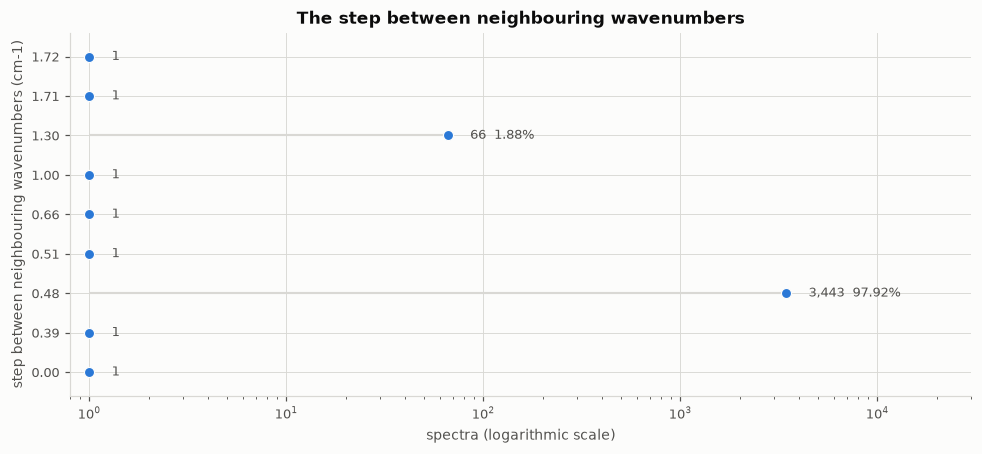

In [9]:
# The trim leaves the grid each export was written on, so the spacing between neighbouring
# wavenumbers is measured here rather than assumed. The step of a file is the median of those
# distances: a mean would be pulled by a file whose axis repeats one wavenumber over hundreds
# of rows and so barely moves.
records = []
for row in data.itertuples():
    x, _ = trimmed[row.path]
    distances = np.diff(x)
    records.append({
        "path": row.path,
        "archive": row.archive,
        "mineral": row.mineral,
        "rruff_id": row.rruff_id,
        "step": float(np.median(distances)),
        "smallest": float(distances.min()),
        "largest": float(distances.max()),
        "distinct": int(np.unique(distances).size),
    })

spacing = pd.DataFrame.from_records(records)
spacing["spread"] = spacing.largest - spacing.smallest
spacing["group"] = spacing.step.round(2)

# The two decimals are only a way of gathering files whose grids differ in the last printed
# digit; the exact range of the step inside each group is reported beside the count.
by_step = spacing.groupby("group").agg(
    spectra=("path", "size"),
    step_from=("step", "min"),
    step_to=("step", "max"),
)
by_step["share_pct"] = (by_step.spectra / len(spacing) * 100).round(2)

print(f"the step between neighbouring wavenumbers, per spectrum, over {len(spacing):,} "
      f"spectra:")
print(by_step.to_string())
print()
print(f"distinct steps: {spacing.step.nunique():,} before grouping to two decimals")
print()
common = by_step.loc[by_step.spectra > 1]
print(f"steps held by more than one spectrum: "
      + ", ".join(f"{step:.2f} cm-1 in {int(count):,}" for step, count in
                  zip(common.index, common.spectra))
      + f", together {int(common.spectra.sum()):,} of {len(spacing):,} spectra")
rare = by_step.loc[by_step.spectra == 1]
print(f"steps held by a single spectrum: {len(rare)}, from {rare.index.min():.2f} to "
      f"{rare.index.max():.2f} cm-1")
print()

# How even the grid is inside one spectrum, for the two steps most spectra are on.
even = spacing[spacing.group.isin(common.index)].groupby("group").agg(
    spectra=("path", "size"),
    distinct_median=("distinct", "median"),
    spread_median=("spread", "median"),
    spread_largest=("spread", "max"),
)
print("how far the distances between neighbours vary inside one spectrum:")
print(even.to_string())
print()

for label, pick in (("the smallest step", spacing.step.idxmin()),
                    ("the largest step", spacing.step.idxmax())):
    row = spacing.loc[pick]
    print(f"{label}: {row['mineral']} {row['rruff_id']}, {row['archive']}, median "
          f"{row.step:.4f} cm-1, distances {row.smallest:g} to {row.largest:g} cm-1, "
          f"{row.distinct:,} distinct")

fig, ax = plt.subplots(figsize=(9.0, 4.2))
rows = np.arange(len(by_step))
# The counts run from 1 to several thousand, so the axis is logarithmic, and each step is
# marked with a point on a line rather than a bar: the length of a bar on a logarithmic axis
# does not read as the count it stands for.
ax.hlines(rows, 1.0, by_step.spectra.values, color=GRID, lw=1.4)
ax.scatter(by_step.spectra.values, rows, s=44, color=BLUE, edgecolor=SURFACE, linewidth=0.8,
           zorder=3)
# The share is printed where a group holds more than one spectrum; beside a count of one
# it only restates the count.
for y, (count, share) in enumerate(zip(by_step.spectra, by_step.share_pct)):
    label = f"{int(count):,}  {share:.2f}%" if count > 1 else f"{int(count):,}"
    ax.text(count * 1.3, y, label, va="center", fontsize=8.5, color=INK_SOFT)
ax.set_yticks(rows)
ax.set_yticklabels([f"{step:.2f}" for step in by_step.index])
ax.set_ylim(-0.6, len(by_step) - 0.4)
ax.set_xscale("log")
ax.set_xlim(0.8, 3e4)
ax.set_xlabel("spectra (logarithmic scale)")
ax.set_ylabel("step between neighbouring wavenumbers (cm-1)")
ax.set_title("The step between neighbouring wavenumbers")
plt.tight_layout()
plt.show()


In [10]:
# Every distance between neighbouring wavenumbers in every spectrum, pooled, and the step
# the data is mostly on. The step is counted twice: once over all the distances, and once
# with a single vote per spectrum, so that a spectrum with more points inside the window
# does not weigh more than a shorter one. The distances are rounded to a millionth of a
# wavenumber so that they group, which is far finer than any printed difference between them.
pooled = np.concatenate([np.diff(x) for x, _ in trimmed.values()])
values, counts = np.unique(np.round(pooled, 6), return_counts=True)

votes = []
for x, _ in trimmed.values():
    own, own_counts = np.unique(np.round(np.diff(x), 6), return_counts=True)
    votes.append(own[own_counts.argmax()])
votes = np.asarray(votes)
_, voted_counts = np.unique(votes, return_counts=True)

step = float(values[counts.argmax()])
near = np.abs(pooled - step) <= 0.001

print(f"distances between neighbouring wavenumbers, pooled over the {len(trimmed):,} "
      f"spectra: {pooled.size:,}")
print(f"the most common step: {step:.4f} cm-1")
print(f"  {int(counts.max()):,} of the distances ({counts.max() / pooled.size * 100:.2f}%)")
print(f"  the most common step of {int(voted_counts.max()):,} spectra "
      f"({voted_counts.max() / votes.size * 100:.2f}%)")
print(f"  distances within 0.001 cm-1 of it: {int(near.sum()):,} ({near.mean() * 100:.2f}%)")
print()
print("the leading steps:")
print(pd.DataFrame({
    "step (cm-1)": [f"{value:.4f}" for value in values],
    "distances": counts,
    "share_pct": (counts / pooled.size * 100).round(2),
    "spectra": [int((votes == value).sum()) for value in values],
}).nlargest(6, "distances").to_string(index=False))


distances between neighbouring wavenumbers, pooled over the 3,516 spectra: 8,279,369
the most common step: 0.4821 cm-1
  5,297,820 of the distances (63.99%)
  the most common step of 3,412 spectra (97.04%)
  distances within 0.001 cm-1 of it: 8,209,193 (99.15%)

the leading steps:
step (cm-1)  distances  share_pct  spectra
     0.4821    5297820      63.99     3412
     0.4820    1629368      19.68       31
     0.4822    1064880      12.86        0
     0.4830     214817       2.59        0
     0.3900       2836       0.03        1
     1.0000       1800       0.02        1


## 7. The intensity scale

An intensity as exported is a photon count on the scale the instrument and the export gave it,
and nothing in the selection rescales it, so each spectrum arrives on its own scale. The two
ends of a spectrum inside the window are the lowest and the highest intensity it holds, and
those are what this section reports.

A spectrum whose lowest value is below zero, or whose highest is not above zero, is one of the
faults the next section counts. The numbers are repeated here because they decide what the
histogram can show: a logarithmic axis has no place for a value at or below zero.


the trimmed set: 3,516 spectra
the lowest intensity a spectrum holds:  median 57.19, smallest above zero 0.000116
the highest intensity a spectrum holds: median 1432, largest of all 5,853,818
spectra whose lowest value is below zero: 68
spectra whose highest value is not above zero: 1

the extremes:
  highest  mineral: Carpathite  rruff_id: R060660  archive: excellent_unoriented  5,853,818
  lowest   mineral: Wolsendorfite  rruff_id: R090051  archive: fair_unoriented  -903.7734
  the spectrum that never rises above zero: Decrespignyite-(Y) R060302, poor_unoriented, -345.1165 to -9.3838

the highest value covers 6.8 decades across the set


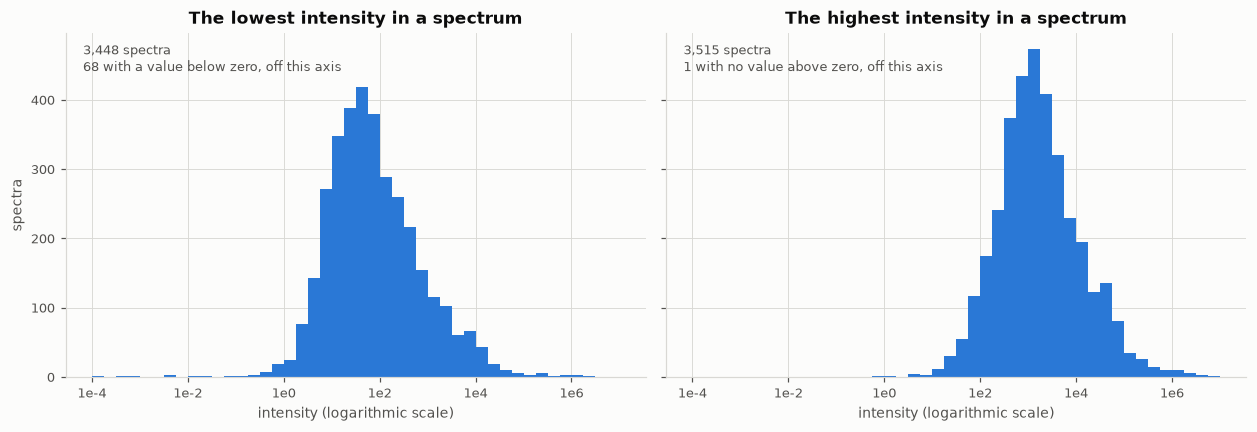

In [11]:
# The lowest and the highest intensity of each spectrum, over the window. Both are drawn on a
# logarithmic axis because the highest runs over several decades; the spectra whose values sit
# at or below zero cannot appear on such an axis and are counted in the text instead.
lowest = data.y_min.values
highest = data.y_max.values
positive_low = lowest[lowest > 0]
positive_high = highest[highest > 0]
below_zero = int((lowest < 0).sum())
never_above_zero = int((highest <= 0).sum())

print(f"the trimmed set: {len(data):,} spectra")
print(f"the lowest intensity a spectrum holds:  median {np.median(positive_low):.4g}, "
      f"smallest above zero {positive_low.min():.4g}")
print(f"the highest intensity a spectrum holds: median {np.median(positive_high):.4g}, "
      f"largest of all {positive_high.max():,.0f}")
print(f"spectra whose lowest value is below zero: {below_zero:,}")
print(f"spectra whose highest value is not above zero: {never_above_zero:,}")
print()
print("the extremes:")
print("  highest  " + "  ".join(
    f"{column}: {data.loc[data.y_max.idxmax(), column]!s}"
    for column in ("mineral", "rruff_id", "archive"))
    + f"  {data.y_max.max():,.0f}")
print("  lowest   " + "  ".join(
    f"{column}: {data.loc[data.y_min.idxmin(), column]!s}"
    for column in ("mineral", "rruff_id", "archive"))
    + f"  {data.y_min.min():,.4f}")
if never_above_zero:
    row = data.loc[data.y_max <= 0].iloc[0]
    print(f"  the spectrum that never rises above zero: {row.mineral} {row.rruff_id}, "
          f"{row.archive}, {row.y_min:.4f} to {row.y_max:.4f}")
print()
print(f"the highest value covers {np.log10(positive_high.max() / positive_high.min()):.1f} "
      f"decades across the set")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)
# A quarter of a decade per bin, over the range the positive values cover. The edges come from
# those values rather than a fixed range, so the drawn range holds every value the text above
# reports: a fixed range leaves the largest intensity in the set off the axis.
logged = np.log10(np.concatenate([positive_low, positive_high]))
low_edge = np.floor(logged.min() * 4) / 4
high_edge = np.ceil(logged.max() * 4) / 4
edges = np.arange(low_edge, high_edge + 0.25, 0.25)
panels = (
    (axes[0], positive_low, "lowest",
     f"{len(positive_low):,} spectra\n{below_zero} with a value below zero, off this axis"),
    (axes[1], positive_high, "highest",
     f"{len(positive_high):,} spectra\n{never_above_zero} with no value above zero, off this "
     f"axis"),
)
for ax, values, end, note in panels:
    ax.hist(np.log10(values), bins=edges, color=BLUE)
    ax.set_title(f"The {end} intensity in a spectrum")
    ax.set_xlabel("intensity (logarithmic scale)")
    # The spectra whose values sit at or below zero cannot be drawn on this axis, so they are
    # named inside the panel where the shape of the histogram leaves them out.
    ax.text(0.03, 0.97, note, transform=ax.transAxes, va="top", ha="left", fontsize=8.5,
            color=INK_SOFT)
    ticks = np.arange(np.ceil(low_edge), np.floor(high_edge) + 1, 2).astype(int)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"1e{tick}" for tick in ticks])
axes[0].set_ylabel("spectra")
plt.tight_layout()
plt.show()


## 8. Values a Raman spectrum cannot take

Every trimmed spectrum is checked, not a sample. Each entry below is a value a Raman spectrum
cannot hold, with the reason:

- **A shift below zero, or the laser line at exactly zero.** Both are impossible once the trim
  has run, since every kept point lies at 100 cm-1 or above. They are counted anyway, because a
  count of zero is what shows the trim did what it claims.
- **A shift at or past the laser's own wavenumber.** The scattered photon would then carry no
  energy: at 532 nm the laser line sits at 18,797 cm-1. The limit is worked out per file from
  that file's own excitation wavelength, so a file reporting none cannot be checked against it.
- **An axis that does not strictly increase, or that repeats a value.** One wavenumber cannot
  carry two intensities. A repeat is one way an axis fails to rise, so it is counted under
  both headings. A repeat before the window, or after it, is gone by now, but a repeat inside
  the window survives the trim.
- **A non-finite intensity.** NaN or infinity is not a count of photons.
- **A negative intensity.** A raw spectrum is a photon count, so it cannot be negative.
- **A spectrum with no variation at all.** The same value at every point measures nothing.

Counted alongside them, without being faults: intensities of exactly zero, intensities that are
all whole numbers, and the longest run of one repeated intensity. The last cell of this section
reports which sources the faulty files come from, by archive and by excitation wavelength.


In [12]:
def longest_identical_run(values):
    """The longest stretch of one value repeated at consecutive positions.

    A run breaks at any difference, including at a NaN, which never equals itself.

    Args:
        values (np.ndarray): the intensities of one spectrum.

    Returns:
        int: the number of positions in that stretch, 1 for a spectrum with no repeats
        and 0 for an empty one.
    """
    if values.size == 0:
        return 0
    same = (np.diff(values) == 0).astype(np.int8)
    edges = np.diff(np.concatenate(([0], same, [0])))
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)
    return int((ends - starts).max()) + 1 if starts.size else 1


def check_points(x, y, wavelength_nm):
    """Count the values one trimmed spectrum holds that a Raman spectrum cannot take.

    Args:
        x, y (np.ndarray): the wavenumbers and intensities inside the window.
        wavelength_nm (float): the file's excitation wavelength, for the laser-line limit,
            or NaN when the file reports none.

    Returns:
        dict: one entry per check holding the number of points that fail it, plus the
        spectrum's own size, the rows failing at least one check counted once each, and
        the lowest intensity.
    """
    steps = np.diff(x)
    finite_y = y[np.isfinite(y)]
    both_finite = bool(np.isfinite(y).all()) if y.size else False
    laser_limit = 1e7 / wavelength_nm if wavelength_nm == wavelength_nm else np.nan

    # The rows failing at least one check, each counted once: a repeat fails both the
    # rising check and the repeat check, and one row of a spectrum should not be counted
    # twice for a single repeat.
    flagged = (x < 0) | (x == 0) | ~np.isfinite(x) | ~np.isfinite(y) | (y < 0)
    if steps.size:
        flagged |= np.concatenate(([False], steps <= 0))
    if laser_limit == laser_limit:
        flagged |= x >= laser_limit

    return {
        "points": int(y.size),
        "flagged": int(flagged.sum()),
        "negative_x": int((x < 0).sum()),
        "rayleigh_x": int((x == 0).sum()),
        "beyond_laser": int((x >= laser_limit).sum()) if laser_limit == laser_limit else 0,
        "non_increasing_x": int((steps <= 0).sum()),
        "repeated_x": int((steps == 0).sum()),
        "nonfinite": int((~np.isfinite(x)).sum() + (~np.isfinite(y)).sum()),
        "negative_y": int((y < 0).sum()),
        "zero_y": int((y == 0).sum()),
        "constant": int(y.size > 0 and both_finite and y.max() == y.min()),
        "integer_y": int(y.size > 0 and both_finite and bool(np.all(y == np.round(y)))),
        "longest_run": longest_identical_run(y),
        "longest_nonzero_run": longest_identical_run(np.where(y == 0, np.nan, y)),
        "y_min": float(finite_y.min()) if finite_y.size else np.nan,
    }


In [13]:
started = time.time()
records = []
for row in data.itertuples():
    x, y = trimmed[row.path]
    counts = check_points(x, y, row.wavelength_nm)
    counts["path"] = row.path
    counts["archive"] = row.archive
    records.append(counts)

checks = pd.DataFrame.from_records(records)
checks["no_laser_limit"] = data.set_index("path").wavelength_nm.reindex(
    checks.path).isna().values

print(f"checked {len(checks):,} trimmed spectra in {time.time() - started:.1f}s")
print(f"files with no excitation wavelength, so no laser limit to check: "
      f"{int(checks.no_laser_limit.sum()):,}")
print()

faults = [
    ("negative_x", "a wavenumber below zero"),
    ("rayleigh_x", "the laser line at exactly zero"),
    ("beyond_laser", "a wavenumber at or past the laser line"),
    ("non_increasing_x", "a wavenumber not greater than the one before it"),
    ("repeated_x", "a wavenumber repeated at a second row"),
    ("nonfinite", "a non-finite wavenumber or intensity"),
    ("negative_y", "a negative intensity"),
    ("constant", "the same intensity at every point"),
]
fault_summary = pd.DataFrame({
    "files": [int((checks[column] > 0).sum()) for column, _ in faults],
    "points": [int(checks[column].sum()) for column, _ in faults],
}, index=[label for _, label in faults])
fault_summary["files_pct"] = (fault_summary.files / len(checks) * 100).round(2)

print(fault_summary.to_string())
print()
for label, value in {
    "files with at least one intensity of exactly zero": int((checks.zero_y > 0).sum()),
    "files whose intensities are all whole numbers": int((checks.integer_y > 0).sum()),
    "longest run of one repeated intensity anywhere": int(checks.longest_run.max()),
    "longest run of one repeated non-zero intensity anywhere":
        int(checks.longest_nonzero_run.max()),
    "files with a non-zero run of 50 identical intensities or more":
        int((checks.longest_nonzero_run >= 50).sum()),
}.items():
    print(f"  {value:7,d}  {label}")
print(f"  {float(checks.y_min.min())!s:>7}  lowest intensity anywhere in the trimmed set")


checked 3,516 trimmed spectra in 0.5s
files with no excitation wavelength, so no laser limit to check: 1

                                                 files  points  files_pct
a wavenumber below zero                              0       0       0.00
the laser line at exactly zero                       0       0       0.00
a wavenumber at or past the laser line               0       0       0.00
a wavenumber not greater than the one before it      2    1742       0.06
a wavenumber repeated at a second row                2    1742       0.06
a non-finite wavenumber or intensity                 0       0       0.00
a negative intensity                                68   16174       1.93
the same intensity at every point                    0       0       0.00

        0  files with at least one intensity of exactly zero
       17  files whose intensities are all whole numbers
       32  longest run of one repeated intensity anywhere
       32  longest run of one repeated non-zero int

In [14]:
# The file-level tally counts a row once however many checks it fails, so it is read from
# the `flagged` column rather than the sum of the per-check columns below. Those columns
# still count a repeated wavenumber under both checks it fails, since a repeat is one way
# for an axis not to rise.
print("files carrying at least one fault, by archive:")
print(pd.DataFrame({
    "files": checks.groupby("archive").size(),
    "with_a_fault": checks.groupby("archive")["flagged"].apply(lambda s: int((s > 0).sum())),
    "points_flagged": checks.groupby("archive")["flagged"].sum(),
}).to_string())
print()
print(f"trimmed files carrying at least one fault: {int((checks.flagged > 0).sum()):,} "
      f"of {len(checks):,}, holding {int(checks.flagged.sum()):,} of "
      f"{int(checks.points.sum()):,} points")
print()
worst = checks.loc[checks.flagged > 0].copy()
worst["name"] = worst.path.map(lambda path: Path(path).name)
worst.sort_values("flagged", ascending=False)[
    ["archive", "name", "points", "flagged", "non_increasing_x", "repeated_x", "negative_x",
     "nonfinite", "negative_y", "beyond_laser"]
].head(20)


files carrying at least one fault, by archive:
                      files  with_a_fault  points_flagged
archive                                                  
excellent_oriented       38             0               0
excellent_unoriented   2524            28            5077
fair_unoriented         489            19            2953
poor_unoriented         276            22            9614
unrated_oriented         15             0               0
unrated_unoriented      174             1             272

trimmed files carrying at least one fault: 70 of 3,516, holding 17,916 of 8,282,885 points



,archive,name,points,flagged,non_increasing_x,repeated_x,negative_x,nonfinite,negative_y,beyond_laser
3123,poor_unoriented,Decrespignyite-(Y)__R060302__Raman__780______R...,2385,2385,0,0,0,0,2385,0
3197,poor_unoriented,Lavinskyite__R141115__Raman__780______Raman_Da...,2385,1882,0,0,0,0,1882,0
498,excellent_unoriented,Chromatite__R130086__Raman__532______Raman_Dat...,2396,1470,1470,1470,0,0,0,0
3305,poor_unoriented,Tyrolite__R050571__Raman__780______Raman_Data_...,2385,1454,0,0,0,0,1454,0
3044,fair_unoriented,Zaratite__R050268__Raman__780______Raman_Data_...,2385,1381,0,0,0,0,1381,0
923,excellent_unoriented,Getchellite__R060109__Raman__780______Raman_Da...,2385,1371,0,0,0,0,1371,0
3056,poor_unoriented,Altaite__R060939__Raman__532______Raman_Data_R...,2385,1274,0,0,0,0,1274,0
3062,poor_unoriented,Argyrodite__R050437__Raman__532______Raman_Dat...,2385,1011,0,0,0,0,1011,0
2897,fair_unoriented,Perovskite__R060345__Raman__780______Raman_Dat...,2385,778,0,0,0,0,778,0
3286,poor_unoriented,Szenicsite__R100179__Raman__780______Raman_Dat...,2385,575,0,0,0,0,575,0


In [15]:
# The faulty files, with the source of each: the archive each was read from and the
# excitation wavelength each reports, the two dimensions counted in section 5. A wavenumber
# repeated at the next row is one way the axis fails to rise, so it is counted under the
# axis. The two faults that occur are the axis and the negative intensity; the printed
# check at the end says whether any file carries both.
faulty = checks.loc[checks.flagged > 0,
                    ["path", "archive", "non_increasing_x", "negative_y"]].merge(
                        data[["path", "wavelength_nm"]], on="path")
faulty["axis_not_rising"] = faulty.non_increasing_x > 0
faulty["negative_intensity"] = faulty.negative_y > 0

everything = data[["path", "archive", "wavelength_nm"]].copy()


def wavelength_name(value):
    """The excitation wavelength as a label, since one file reports none.

    Args:
        value (float): the wavelength in nm, or NaN when the field holds no number.

    Returns:
        str: the wavelength, or a label standing in where the field holds no number.
    """
    return "no wavelength reported" if pd.isna(value) else f"{value:g} nm"


for frame in (faulty, everything):
    frame["wavelength"] = frame.wavelength_nm.map(wavelength_name)


def source_table(column):
    """The faulty files of each source, beside every file of that source.

    Args:
        column (str): the source to group by, 'archive' or 'wavelength'.

    Returns:
        pd.DataFrame: one row per source, the sources with the most faulty files first.
    """
    table = everything.groupby(column).size().rename("files").to_frame()
    table["axis not rising"] = faulty.loc[faulty.axis_not_rising, column].value_counts()
    table["negative intensity"] = faulty.loc[faulty.negative_intensity, column].value_counts()
    table = table.fillna(0).astype(int)
    table["with a fault"] = table["axis not rising"] + table["negative intensity"]
    table["percent"] = (table["with a fault"] / table.files * 100).round(2)
    return table.sort_values("with a fault", ascending=False)


print(f"{len(faulty):,} of the {len(data):,} trimmed files carry at least one fault, from "
      f"{faulty.archive.nunique()} of the {data.archive.nunique()} archives and "
      f"{faulty.wavelength.nunique()} of the {everything.wavelength.nunique()} excitation "
      f"wavelengths")
print()
print("by archive:")
print(source_table("archive").to_string())
print()
print("by excitation wavelength:")
print(source_table("wavelength").to_string())
print()
print(f"files carrying both kinds of fault: "
      f"{int((faulty.axis_not_rising & faulty.negative_intensity).sum()):,}")


70 of the 3,516 trimmed files carry at least one fault, from 4 of the 6 archives and 5 of the 6 excitation wavelengths

by archive:
                      files  axis not rising  negative intensity  with a fault  percent
archive                                                                                
excellent_unoriented   2524                1                  27            28     1.11
poor_unoriented         276                0                  22            22     7.97
fair_unoriented         489                0                  19            19     3.89
unrated_unoriented      174                1                   0             1     0.57
excellent_oriented       38                0                   0             0     0.00
unrated_oriented         15                0                   0             0     0.00

by excitation wavelength:
                        files  axis not rising  negative intensity  with a fault  percent
wavelength                                     

## 9. What this covers

| Section | Reports |
| --- | --- |
| 4 | the files the window selects, and the trimmed set they make |
| 5 | where the spectra come from, by archive and by excitation wavelength, in files and points |
| 6 | the step between neighbouring wavenumbers in each spectrum, and the step most of the data is on |
| 7 | the lowest and the highest intensity each spectrum holds |
| 8 | the values the trimmed spectra hold that a Raman spectrum cannot take, and the sources the faulty files come from |

The window itself, and the counts behind the choice of it, are in
`notebooks/rruff_raw.ipynb`; this notebook starts from the decision recorded there.


## 10. Reproducing

```
cd /home/raj/projects/SH_Project
jupyter execute --inplace --kernel_name sh_project notebooks/selected_data_eda.ipynb
```

The archives are read from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is set. No
private data is needed: everything below is counted from the exports themselves.
